Delio Fernando Palacios Viafara - 30000115782

# Modelo de Clasificación Multiclase mediante Redes Neuronales Recurrentes LSTM para la Identificación de Dispositivos Eléctricos

**Dataset:** [ElectricDevices](https://www.timeseriesclassification.com/description.php?Dataset=ElectricDevices) (UCR Time Series Classification Archive)  
**Instancias:** 13,973 registros de consumo eléctrico.  
**Clases (7):** 1-7 (dispositivos eléctricos que no se especifican ni en la web ni el dataset)

## Instalación e importaciones

In [66]:
%pip install tslearn

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslearn.datasets import UCR_UEA_datasets
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical


## Carga del dataset

In [68]:
ucr = UCR_UEA_datasets()
X_train_raw, y_train_raw, X_test_raw, y_test_raw = ucr.load_dataset("ElectricDevices")

print(f"X_train: {X_train_raw.shape}  →  (muestras, timesteps, features)")
print(f"y_train: {y_train_raw.shape}")
print(f"X_test:  {X_test_raw.shape}")
print(f"y_test:  {y_test_raw.shape}")
print(f"\nClases únicas: {np.unique(y_train_raw)}")
print(f"Total de clases: {len(np.unique(y_train_raw))}")

X_train: (8926, 96, 1)  →  (muestras, timesteps, features)
y_train: (8926,)
X_test:  (7711, 96, 1)
y_test:  (7711,)

Clases únicas: [1 2 3 4 5 6 7]
Total de clases: 7


## Preprocesamiento y Limpieza de Datos

1. **Fusión:** Combinación de train y test para redistribuir con validación.
2. **Codificación:** Ajuste de etiquetas a índices 0-based (si no lo están ya).
3. **Estandarización:** Escalado de la señal de consumo eléctrico.
4. **Codificación one-hot:** Preparación de etiquetas para clasificación multiclase.

In [69]:
X_all = np.concatenate([X_train_raw, X_test_raw], axis=0)
y_all = np.concatenate([y_train_raw, y_test_raw], axis=0)

print(f"Etiquetas originales únicas: {np.unique(y_all)}")

if y_all.min() != 0:
    y_encoded = (y_all - y_all.min()).astype(int)
    print(f"Ajustadas a 0-indexed: {np.unique(y_encoded)}")
else:
    y_encoded = y_all.astype(int)

NUM_CLASSES = len(np.unique(y_encoded))
print(f"Total de clases: {NUM_CLASSES}")
print(f"Shape X: {X_all.shape}")
print(f"Shape y: {y_encoded.shape}")

Etiquetas originales únicas: [1 2 3 4 5 6 7]
Ajustadas a 0-indexed: [0 1 2 3 4 5 6]
Total de clases: 7
Shape X: (16637, 96, 1)
Shape y: (16637,)


In [70]:
n_samples, n_timesteps, n_features = X_all.shape

X_flat = X_all.reshape(n_samples, n_timesteps * n_features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_flat).reshape(n_samples, n_timesteps, n_features)

y_categorical = to_categorical(y_encoded, num_classes=NUM_CLASSES)

print(f"X_scaled: {X_scaled.shape}  →  (muestras, timesteps, features)")
print(f"y_categorical: {y_categorical.shape}  →  (muestras, num_clases)")

X_scaled: (16637, 96, 1)  →  (muestras, timesteps, features)
y_categorical: (16637, 7)  →  (muestras, num_clases)


## Análisis Exploratorio de Datos

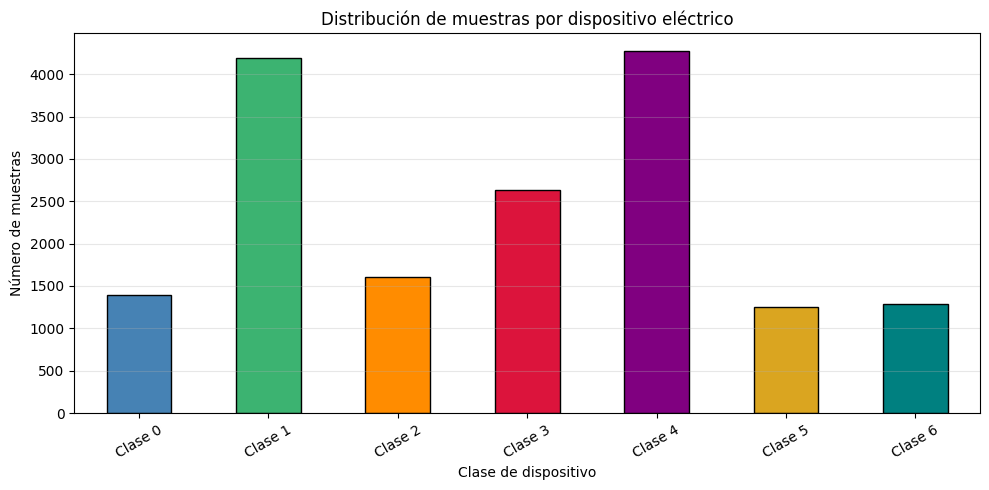


Estadísticas por clase:
count       7.0
mean     2376.7
std      1352.0
min      1252.0
25%      1339.0
50%      1606.0
75%      3413.0
max      4275.0
Name: count, dtype: float64


In [71]:
clases = pd.Series(y_encoded).value_counts().sort_index()

plt.figure(figsize=(10, 5))
clases.plot(kind='bar', color=['steelblue', 'mediumseagreen', 'darkorange', 'crimson', 'purple', 'goldenrod', 'teal'], edgecolor='black')
plt.title('Distribución de muestras por dispositivo eléctrico')
plt.xlabel('Clase de dispositivo')
plt.ylabel('Número de muestras')
plt.xticks(ticks=range(NUM_CLASSES), labels=[f'Clase {i}' for i in range(NUM_CLASSES)], rotation=30)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nEstadísticas por clase:")
print(clases.describe().round(1))

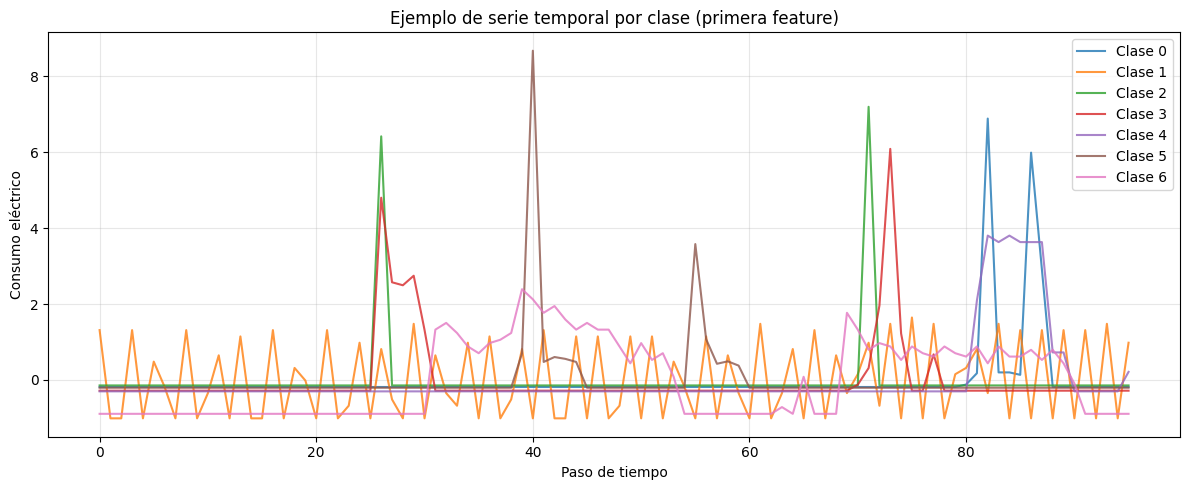

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(NUM_CLASSES):
    idx = np.where(y_encoded == i)[0][0]
    plt.plot(X_all[idx, :, 0], label=f"Clase {i}", alpha=0.8)

plt.title('Ejemplo de serie temporal por clase (consumo eléctrico)')
plt.xlabel('Paso de tiempo')
plt.ylabel('Consumo eléctrico')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## División de Datos

In [73]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y_categorical, test_size=0.30, random_state=42, stratify=y_encoded
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp.argmax(axis=1)
)

print(f"Train:      {X_train.shape[0]:,} muestras")
print(f"Validación: {X_val.shape[0]:,} muestras")
print(f"Test:       {X_test.shape[0]:,} muestras")
print(f"\nInput shape por muestra: {X_train.shape[1:]}")

Train:      11,645 muestras
Validación: 2,496 muestras
Test:       2,496 muestras

Input shape por muestra: (96, 1)


## Arquitectura del Modelo: Red Neuronal LSTM

In [74]:
def crear_modelo_lstm(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.LSTM(128, return_sequences=True),
        layers.BatchNormalization(),
        layers.Dropout(0.4),

        layers.LSTM(64, return_sequences=True),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.LSTM(32),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(32, activation='relu'),
        layers.Dropout(0.2),

        layers.Dense(num_classes, activation='softmax')
    ])
    return model

In [75]:
modelo = crear_modelo_lstm(X_train.shape[1:], NUM_CLASSES)
modelo.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_9 (LSTM)                   │ (None, 96, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 96, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 96, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 96, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 96, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 133,703 (522.28 KB)

 Trainable params: 133,255 (520.53 KB)

 Non-trainable params: 448 (1.75 KB)

## Compilación y Callbacks

In [76]:
modelo.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [77]:
early_stop = EarlyStopping(
    monitor='val_accuracy',
    mode='max',
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

callbacks = [early_stop, reduce_lr]

## Entrenamiento del Modelo

In [78]:
historial = modelo.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.5114 - loss: 1.3653 - val_accuracy: 0.4948 - val_loss: 1.3889 - learning_rate: 0.0010
Epoch 2/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.6002 - loss: 1.1241 - val_accuracy: 0.6410 - val_loss: 0.9925 - learning_rate: 0.0010
Epoch 3/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.6277 - loss: 1.0488 - val_accuracy: 0.6751 - val_loss: 0.9063 - learning_rate: 0.0010
Epoch 4/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.6662 - loss: 0.9614 - val_accuracy: 0.6971 - val_loss: 0.8313 - learning_rate: 0.0010
Epoch 5/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.6995 - loss: 0.8722 - val_accuracy: 0.6711 - val_loss: 0.9538 - learning_rate: 0.0010
Epoch 6/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7094 - loss: 0.8469 - val_accuracy: 0.7360 - val_loss: 0.7439 - learning_rate: 0.0010
Epoch 7/60
364/364 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.7321 - loss: 0

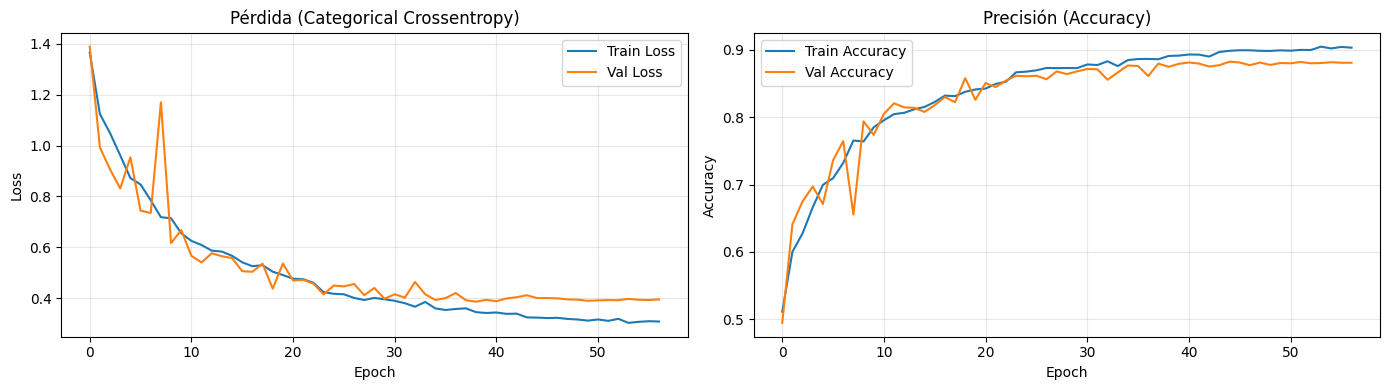

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(historial.history['loss'], label='Train Loss')
axes[0].plot(historial.history['val_loss'], label='Val Loss')
axes[0].set_title('Pérdida (Categorical Crossentropy)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(historial.history['accuracy'], label='Train Accuracy')
axes[1].plot(historial.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Precisión (Accuracy)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Evaluación en el Conjunto de Test

In [80]:
y_pred_proba = modelo.predict(X_test)
y_pred = y_pred_proba.argmax(axis=1)
y_true = y_test.argmax(axis=1)

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [81]:
accuracy = accuracy_score(y_true, y_pred)
print(f"=== Métricas de Clasificación (LSTM) ===")
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)\n")

print("Reporte de clasificación:")
print(classification_report(y_true, y_pred, target_names=[f'Clase {i}' for i in range(NUM_CLASSES)]))

=== Métricas de Clasificación (LSTM) ===
Accuracy: 0.8770 (87.70%)

Reporte de clasificación:
              precision    recall  f1-score   support

     Clase 0       0.89      0.84      0.87       209
     Clase 1       0.99      0.97      0.98       628
     Clase 2       0.75      0.84      0.79       241
     Clase 3       0.77      0.86      0.81       396
     Clase 4       0.92      0.89      0.90       642
     Clase 5       0.93      0.87      0.90       188
     Clase 6       0.73      0.66      0.69       192

    accuracy                           0.88      2496
   macro avg       0.85      0.85      0.85      2496
weighted avg       0.88      0.88      0.88      2496



<Figure size 1000x700 with 0 Axes>

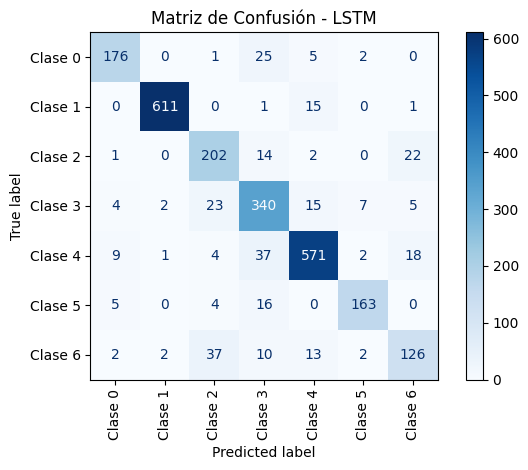

In [83]:
cm = confusion_matrix(y_true, y_pred)
class_labels = [f'Clase {i}' for i in range(NUM_CLASSES)]

plt.figure(figsize=(10, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels).plot(
    cmap='Blues',
    xticks_rotation=90
)
plt.title('Matriz de Confusión - LSTM')
plt.tight_layout()
plt.show()